# Supervenn of Ensembl IDs across the first four tabs

Reads the first column (Ensembl ID) of the first four tabs of the Google Sheet, removes the version suffix (`ENSG00000141510.18` becomes `ENSG00000141510`), and draws a [supervenn](https://github.com/gecko984/supervenn) with the tab names as sample labels.

In [ ]:
!pip install -q supervenn

In [ ]:
import re
import pandas
import matplotlib.pyplot
from supervenn import supervenn

## Settings

In [ ]:
spreadsheet_id = '13G-It9TCj5RYVmi39G9HgsL-g4VHrWM2IhSpIfqrBrA'
number_of_tabs = 4

## Read the first column of each tab

The sheet is shared with anyone who has the link, so it is downloaded directly as an Excel file, no login needed.

In [ ]:
export_url = f'https://docs.google.com/spreadsheets/d/{spreadsheet_id}/export?format=xlsx'
all_tabs = pandas.read_excel(export_url, sheet_name=None, header=None, dtype=str)

raw_columns = {}
for tab_name in list(all_tabs.keys())[:number_of_tabs]:
    raw_columns[tab_name] = all_tabs[tab_name].iloc[:, 0].dropna().tolist()
    print(tab_name, ':', len(raw_columns[tab_name]), 'cells in column A, first values:', raw_columns[tab_name][:3])

PC low vs disease : 772 cells in column A, first values: ['ENSEMBL ID', 'ENSG00000003137', 'ENSG00000095596']
BP low vs disease : 735 cells in column A, first values: ['ENSEMBL ID', 'ENSG00000095596.12', 'ENSG00000162496.9']
PC high vs disease : 929 cells in column A, first values: ['ENSEMBL ID', 'ENSG00000003137', 'ENSG00000095596']
BP high vs disease : 1242 cells in column A, first values: ['ENSEMBL ID', 'ENSG00000162496.9', 'ENSG00000178726.7']


## Clean the IDs and trim the version

Only cells that look like Ensembl IDs are kept, so the header row and empty cells are dropped automatically. The version (`.18`) is removed, but a `_PAR_Y` suffix (GENCODE pseudoautosomal copies) is kept, so the X and Y copies of a PAR gene are not merged.

In [ ]:
ensembl_pattern = re.compile(r'^(ENS[A-Z]*\d{11})(\.\d+)?(_PAR_Y)?$')


def trim_version(value):
    value = str(value).strip()
    match = ensembl_pattern.match(value)
    if match is None:
        return None
    stable_id = match.group(1)
    if match.group(3) is not None:
        stable_id = stable_id + match.group(3)
    return stable_id


gene_sets = {}
for tab_name, values in raw_columns.items():
    trimmed = []
    not_ensembl = []
    for value in values:
        stable_id = trim_version(value)
        if stable_id is None:
            if str(value).strip() != '':
                not_ensembl.append(value)
        else:
            trimmed.append(stable_id)
    gene_sets[tab_name] = set(trimmed)
    with_version = sum(['.' in str(value) for value in values])
    print(f'{tab_name}: {len(trimmed)} IDs ({with_version} had a version), {len(gene_sets[tab_name])} unique after trimming')
    if len(trimmed) > len(gene_sets[tab_name]):
        print(f'    {len(trimmed) - len(gene_sets[tab_name])} duplicates collapsed (same gene, different or repeated version)')
    if len(not_ensembl) > 0:
        print(f'    skipped {len(not_ensembl)} cells that are not Ensembl IDs, for example: {not_ensembl[:5]}')

PC low vs disease: 771 IDs (0 had a version), 771 unique after trimming
    skipped 1 cells that are not Ensembl IDs, for example: ['ENSEMBL ID']
BP low vs disease: 734 IDs (734 had a version), 734 unique after trimming
    skipped 1 cells that are not Ensembl IDs, for example: ['ENSEMBL ID']
PC high vs disease: 928 IDs (0 had a version), 928 unique after trimming
    skipped 1 cells that are not Ensembl IDs, for example: ['ENSEMBL ID']
BP high vs disease: 1241 IDs (1241 had a version), 1241 unique after trimming
    skipped 1 cells that are not Ensembl IDs, for example: ['ENSEMBL ID']


## Supervenn

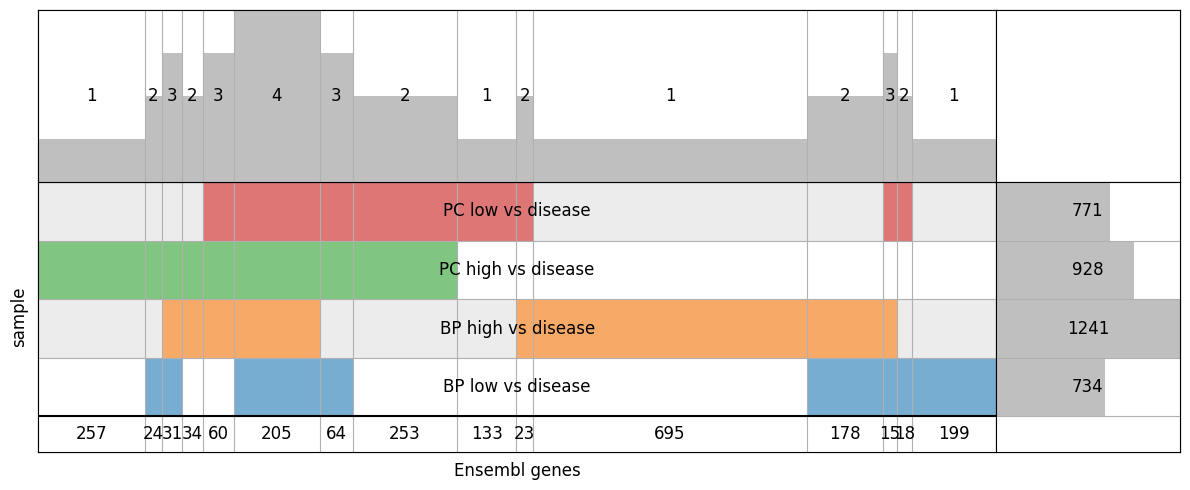

In [ ]:
labels = list(gene_sets.keys())
sets = [gene_sets[label] for label in labels]

figure = matplotlib.pyplot.figure(figsize=(12, 5))
supervenn(sets, labels, side_plot_width=1.5, widths_minmax_ratio=0.05, sets_ordering='minimize gaps', min_width_for_annotation=5)
matplotlib.pyplot.xlabel('Ensembl genes')
matplotlib.pyplot.ylabel('sample')
matplotlib.pyplot.tight_layout()
figure.savefig('supervenn_ensembl.pdf')
figure.savefig('supervenn_ensembl.png', dpi=300)
matplotlib.pyplot.show()

## Which genes are in each region

One row per gene, True or False for each sample, and the combination it belongs to. Saved as `supervenn_ensembl_membership.tsv` in the Colab file panel.

In [ ]:
all_genes = sorted(set.union(*sets))
membership = pandas.DataFrame(index=all_genes)
membership.index.name = 'ensembl id'
for label in labels:
    membership[label] = [gene in gene_sets[label] for gene in all_genes]

membership['present in'] = membership[labels].apply(lambda row: ' & '.join([label for label in labels if row[label]]), axis=1)
membership['number of samples'] = membership[labels].sum(axis=1)
membership = membership.sort_values(['number of samples', 'present in'], ascending=[False, True])
membership.to_csv('supervenn_ensembl_membership.tsv', sep='\t')

print(membership['present in'].value_counts().to_string())

present in
BP high vs disease                                                                 695
PC high vs disease                                                                 257
PC low vs disease & PC high vs disease                                             253
PC low vs disease & BP low vs disease & PC high vs disease & BP high vs disease    205
BP low vs disease                                                                  199
BP low vs disease & BP high vs disease                                             178
PC low vs disease                                                                  133
PC low vs disease & BP low vs disease & PC high vs disease                          64
PC low vs disease & PC high vs disease & BP high vs disease                         60
PC high vs disease & BP high vs disease                                             34
BP low vs disease & PC high vs disease & BP high vs disease                         31
BP low vs disease & PC high vs d

In [ ]:
# genes present in all samples
shared_by_all = membership[membership['number of samples'] == len(labels)].index.tolist()
print(len(shared_by_all), 'genes in all samples')
print(shared_by_all[:50])

205 genes in all samples
['ENSG00000003137', 'ENSG00000003436', 'ENSG00000004468', 'ENSG00000004660', 'ENSG00000005001', 'ENSG00000006283', 'ENSG00000006606', 'ENSG00000006747', 'ENSG00000019186', 'ENSG00000020181', 'ENSG00000036672', 'ENSG00000046653', 'ENSG00000049130', 'ENSG00000050405', 'ENSG00000053747', 'ENSG00000069849', 'ENSG00000072041', 'ENSG00000076716', 'ENSG00000077092', 'ENSG00000079257', 'ENSG00000082482', 'ENSG00000088826', 'ENSG00000095303', 'ENSG00000095596', 'ENSG00000100003', 'ENSG00000100292', 'ENSG00000102265', 'ENSG00000105519', 'ENSG00000105825', 'ENSG00000106483', 'ENSG00000106511', 'ENSG00000106809', 'ENSG00000106976', 'ENSG00000107731', 'ENSG00000108960', 'ENSG00000109819', 'ENSG00000110492', 'ENSG00000111341', 'ENSG00000112902', 'ENSG00000113361', 'ENSG00000115232', 'ENSG00000115641', 'ENSG00000118257', 'ENSG00000118849', 'ENSG00000119514', 'ENSG00000119714', 'ENSG00000122035', 'ENSG00000122420', 'ENSG00000122786', 'ENSG00000122861']
